In [6]:
# Import libraries

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense, Dropout

from tensorflow.keras.callbacks import EarlyStopping

import matplotlib.pyplot as plt
import time
import pandas as pd

In [7]:
#  Load and preprocess IMDb Dataset



vocab_size = 10000
max_length = 200


(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)


# Padding sequences

x_train = pad_sequences(
    x_train,
    maxlen=max_length
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length
)


print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [8]:
#  Early Stopping



early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)


In [9]:
# Build LSTM Model
def create_lstm():

    model = Sequential()


    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=128,
            input_length=max_length
        )
    )


    model.add(
        LSTM(
            64,
            dropout=0.2,
            recurrent_dropout=0.2
        )
    )


    model.add(
        Dropout(0.5)
    )


    model.add(
        Dense(
            1,
            activation='sigmoid'
        )
    )


    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )


    return model

In [10]:
# Build GRU Model
def create_gru():

    model = Sequential()


    model.add(
        Embedding(
            input_dim=vocab_size,
            output_dim=128,
            input_length=max_length
        )
    )


    model.add(
        GRU(
            64,
            dropout=0.2,
            recurrent_dropout=0.2
        )
    )


    model.add(
        Dropout(0.5)
    )


    model.add(
        Dense(
            1,
            activation='sigmoid'
        )
    )


    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )


    return model


In [12]:
# Train LSTM
lstm_model = create_lstm()


print("\nTraining LSTM Model...")


start_time = time.time()


history_lstm = lstm_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)


lstm_time = time.time() - start_time



lstm_loss, lstm_accuracy = lstm_model.evaluate(
    x_test,
    y_test
)


print("LSTM Accuracy:", lstm_accuracy)
print("LSTM Training Time:", lstm_time)


Training LSTM Model...
Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 106s 324ms/step - accuracy: 0.7607 - loss: 0.5000 - val_accuracy: 0.8390 - val_loss: 0.3701
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 324ms/step - accuracy: 0.8597 - loss: 0.3444 - val_accuracy: 0.8414 - val_loss: 0.3699
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 325ms/step - accuracy: 0.8820 - loss: 0.2963 - val_accuracy: 0.8100 - val_loss: 0.4211
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 101s 321ms/step - accuracy: 0.9072 - loss: 0.2406 - val_accuracy: 0.8596 - val_loss: 0.3709
782/782 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step - accuracy: 0.8404 - loss: 0.3684
LSTM Accuracy: 0.8404399752616882
LSTM Training Time: 490.63064455986023


In [13]:
#  Train GRU



gru_model = create_gru()


print("\nTraining GRU Model...")


start_time = time.time()


history_gru = gru_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)


gru_time = time.time() - start_time



gru_loss, gru_accuracy = gru_model.evaluate(
    x_test,
    y_test
)

print("GRU Accuracy:", gru_accuracy)
print("GRU Training Time:", gru_time)


Training GRU Model...
Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 104s 322ms/step - accuracy: 0.7254 - loss: 0.5329 - val_accuracy: 0.7726 - val_loss: 0.5044
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 98s 315ms/step - accuracy: 0.8523 - loss: 0.3590 - val_accuracy: 0.8420 - val_loss: 0.3569
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 310ms/step - accuracy: 0.8888 - loss: 0.2843 - val_accuracy: 0.8478 - val_loss: 0.3726
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 315ms/step - accuracy: 0.9071 - loss: 0.2397 - val_accuracy: 0.8438 - val_loss: 0.3699
782/782 ━━━━━━━━━━━━━━━━━━━━ 30s 38ms/step - accuracy: 0.8453 - loss: 0.3600
GRU Accuracy: 0.8453199863433838
GRU Training Time: 486.8311643600464


In [14]:
# Results Comparison



results = pd.DataFrame(
    {
        "Model": ["LSTM", "GRU"],

        "Accuracy":
        [
            lstm_accuracy,
            gru_accuracy
        ],

        "Loss":
        [
            lstm_loss,
            gru_loss
        ],

        "Training Time (seconds)":
        [
            lstm_time,
            gru_time
        ],

        "Epochs Used":
        [
            len(history_lstm.history['loss']),
            len(history_gru.history['loss'])
        ]

    }
)


print("\nModel Comparison")
print(results)


Model Comparison
  Model  Accuracy      Loss  Training Time (seconds)  Epochs Used
0  LSTM   0.84044  0.368395               490.630645            4
1   GRU   0.84532  0.359999               486.831164            4


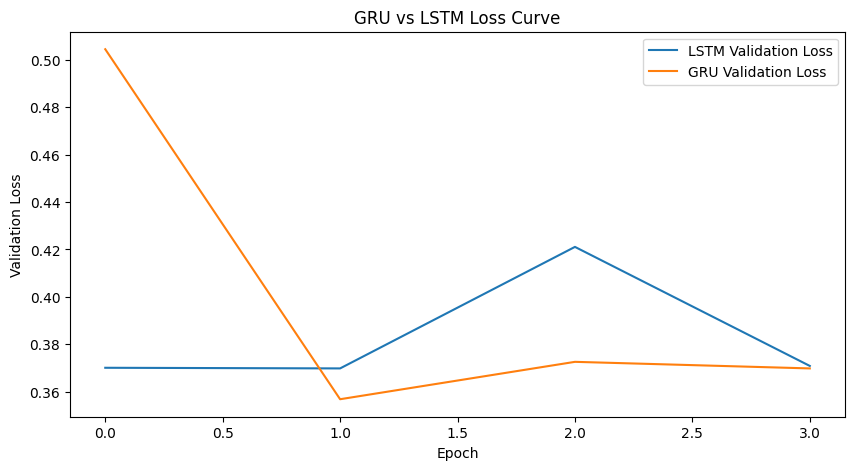

In [15]:
#  Loss Curve Comparison



plt.figure(figsize=(10,5))


plt.plot(
    history_lstm.history['val_loss'],
    label="LSTM Validation Loss"
)


plt.plot(
    history_gru.history['val_loss'],
    label="GRU Validation Loss"
)


plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.title(
    "GRU vs LSTM Loss Curve"
)

plt.legend()

plt.show()


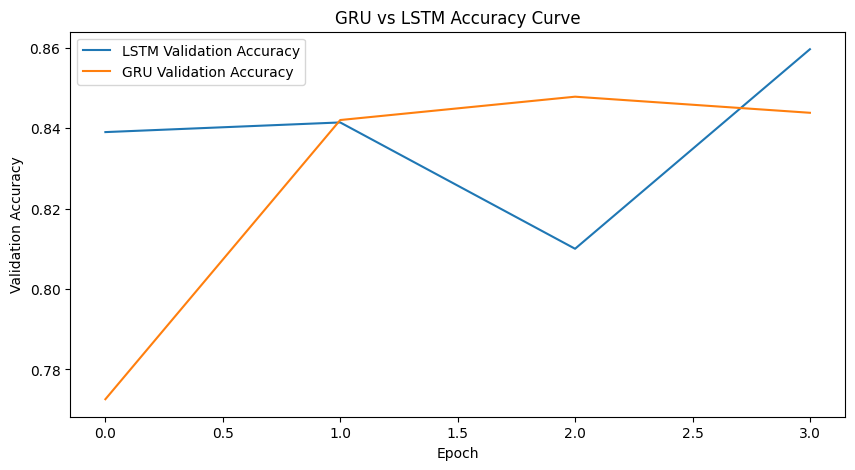

In [16]:
# Accuracy Curve Comparison



plt.figure(figsize=(10,5))


plt.plot(
    history_lstm.history['val_accuracy'],
    label="LSTM Validation Accuracy"
)


plt.plot(
    history_gru.history['val_accuracy'],
    label="GRU Validation Accuracy"
)


plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")


plt.title(
    "GRU vs LSTM Accuracy Curve"
)


plt.legend()

plt.show()


In [17]:
#  Final Analysis



print("\nFinal Analysis:")

if gru_time < lstm_time:
    print(
        "GRU trained faster than LSTM because it has fewer gates and parameters."
    )

else:
    print(
        "LSTM trained faster in this experiment."
    )


if gru_accuracy > lstm_accuracy:
    print(
        "GRU achieved better accuracy in this experiment."
    )

else:
    print(
        "LSTM achieved better accuracy in this experiment."
    )


Final Analysis:
GRU trained faster than LSTM because it has fewer gates and parameters.
GRU achieved better accuracy in this experiment.
